# Weekly Test 14 - Model Training (Week 14, Days 66-70)

All tuning and model selection below use only `X_train` and the same five stratified folds. Test predictions are made once per final model; the threshold table and bootstrap reuse those predictions and do not tune either model. Logistic Regression follows Day 64C's `class_weight='balanced'` choice.

`data/processed/y_test.csv` is not present in this checkout. If it remains absent, the setup cell explicitly falls back to the `actual` column in `logreg_test_predictions.csv`, after checking that its row count matches `X_test`.

Train: (4226, 8); test: (1057, 8); churn share train/test: 0.566/0.566

SECTION A - LOGISTIC REGRESSION
Initial model n_iter_=23; converged=True; ConvergenceWarnings=0


,max_iter,n_iter,train_log_loss,convergence_warnings
0,1,1,0.5615,1
1,2,2,0.5524,1
2,5,5,0.5468,1
3,10,10,0.5459,1
4,50,23,0.5450,0
5,200,23,0.5450,0


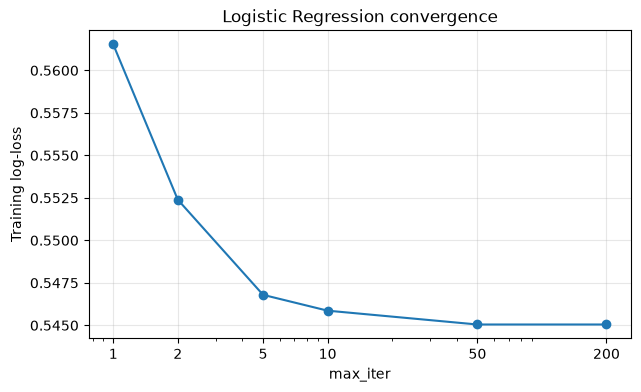

Loss is within 0.001 of the best observed value by max_iter=10.
It is effectively flat between max_iter=50 and 200.


,C,train_f1,cv_f1,cv_std,gap_train_minus_cv
0,0.001,0.7468,0.7437,0.0169,0.0030
1,0.010,0.7448,0.7437,0.0105,0.0012
2,0.100,0.7456,0.7460,0.0091,-0.0004
3,1.000,0.7468,0.7455,0.0098,0.0013
4,10.000,0.7467,0.7451,0.0091,0.0017
5,100.000,0.7467,0.7448,0.0092,0.0019


Chosen C=0.1: highest mean training-CV F1 (0.7460); test data did not influence C.
Same selected C=0.1: scaled n_iter_=22 (warnings=0); unscaled n_iter_=257 (warnings=0).
Scaling puts numeric features on comparable ranges, typically improving optimizer convergence; the observed iteration counts and warnings above are the evidence for this dataset.

SECTION C - DECISION TREE
Unlimited tree depth=36, leaves=1066, train accuracy=1.000
CV train F1=1.000; CV F1=0.686; gap=0.314 (overfitting / high variance).


,max_depth,train_f1,cv_f1,cv_std,gap
0,1,0.739,0.736,0.007,0.003
1,2,0.739,0.736,0.007,0.003
2,3,0.734,0.716,0.031,0.019
3,4,0.734,0.717,0.010,0.017
4,5,0.764,0.736,0.011,0.028
5,6,0.774,0.725,0.009,0.048
6,8,0.807,0.701,0.022,0.106
7,10,0.852,0.694,0.024,0.158
8,15,0.959,0.684,0.013,0.275
9,20,0.994,0.679,0.012,0.315


Best mean CV F1: 0.736 at depth 1; one-SE simplest depth: 1; depth difference: 0.


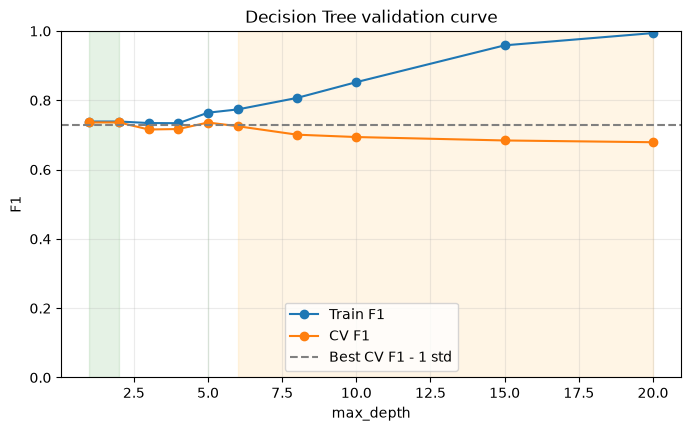

**Underfit:** depths below the near-best band. **Sweet spot:** depths within one standard error of the best CV F1. **Overfit:** deeper trees past that band, especially as the train-CV gap grows.

,min_samples_leaf,train_f1,cv_f1
0,1,0.852,0.694
1,5,0.824,0.693
2,10,0.812,0.713
3,20,0.797,0.730
4,50,0.773,0.731
5,100,0.759,0.739
6,200,0.753,0.736


CV-F1 range: max_depth=0.057; min_samples_leaf=0.046. On this grid, leaf size is less influential by this range measure.
GridSearchCV best_params_ (training CV only): {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 50, 'min_samples_split': 2}


,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_max_depth,param_min_samples_leaf,param_min_samples_split,param_criterion
0,1,0.7482,0.0047,0.7640,5,50,2,entropy
1,1,0.7482,0.0047,0.7640,5,50,20,entropy
2,1,0.7482,0.0047,0.7640,5,50,50,entropy
3,4,0.7452,0.0093,0.7707,6,20,50,entropy
4,5,0.7448,0.0143,0.7687,6,50,2,entropy
5,5,0.7448,0.0143,0.7687,6,50,20,entropy
6,5,0.7448,0.0143,0.7687,6,50,50,entropy
7,8,0.7446,0.0114,0.7625,5,20,50,entropy


Best mean CV F1=0.7482; one-SE-simple choice={'max_depth': np.int64(5), 'min_samples_leaf': np.int64(50), 'min_samples_split': np.int64(50), 'criterion': 'entropy'}. Similar scores favor a shallower tree, larger leaves/split minimums, and gini only as a final tie-break.

SECTION B - FINAL LOGISTIC REGRESSION PREDICTIONS
Final scaled LogReg n_iter_=22; unscaled counterpart n_iter_=257; warnings scaled/unscaled=0/0.
predict() equals (predict_proba()[:, 1] >= 0.5): True
Row 0: intercept + dot = 0.72368522; sigmoid = 0.67341801; predict_proba = 0.67341801; match=True


,threshold,flagged_customers,precision,recall
0,0.3,813,0.683,0.928
1,0.4,688,0.735,0.846
2,0.5,556,0.795,0.739
3,0.6,441,0.812,0.599
4,0.7,317,0.839,0.445


Never select a threshold from this test table: that would adapt to the exam answers. Choose it using training-only out-of-fold/validation probabilities (or nested CV), then lock it before test evaluation.
Chosen tree root: Recency <= 125.5
|--- Recency <= 125.50
|   |--- Frequency <= 7.50
|   |   |--- Monetary_log <= 7.03
|   |   |   |--- Recency <= 65.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Recency >  65.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Monetary_log >  7.03
|   |   |   |--- Tenure <= 425.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Tenure >  425.00
|   |   |   |   |--- truncated branch of depth 2
|   |--- Frequency >  7.50
|   |   |--- Monetary_log <= 7.68
|   |   |   |--- class: 0
|   |   |--- Monetary_log >  7.68
|   |   |   |--- Frequency <= 12.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Frequency >  12.50
|   |   |   |   |--- truncated branch of depth 2
|--- Recency >  125

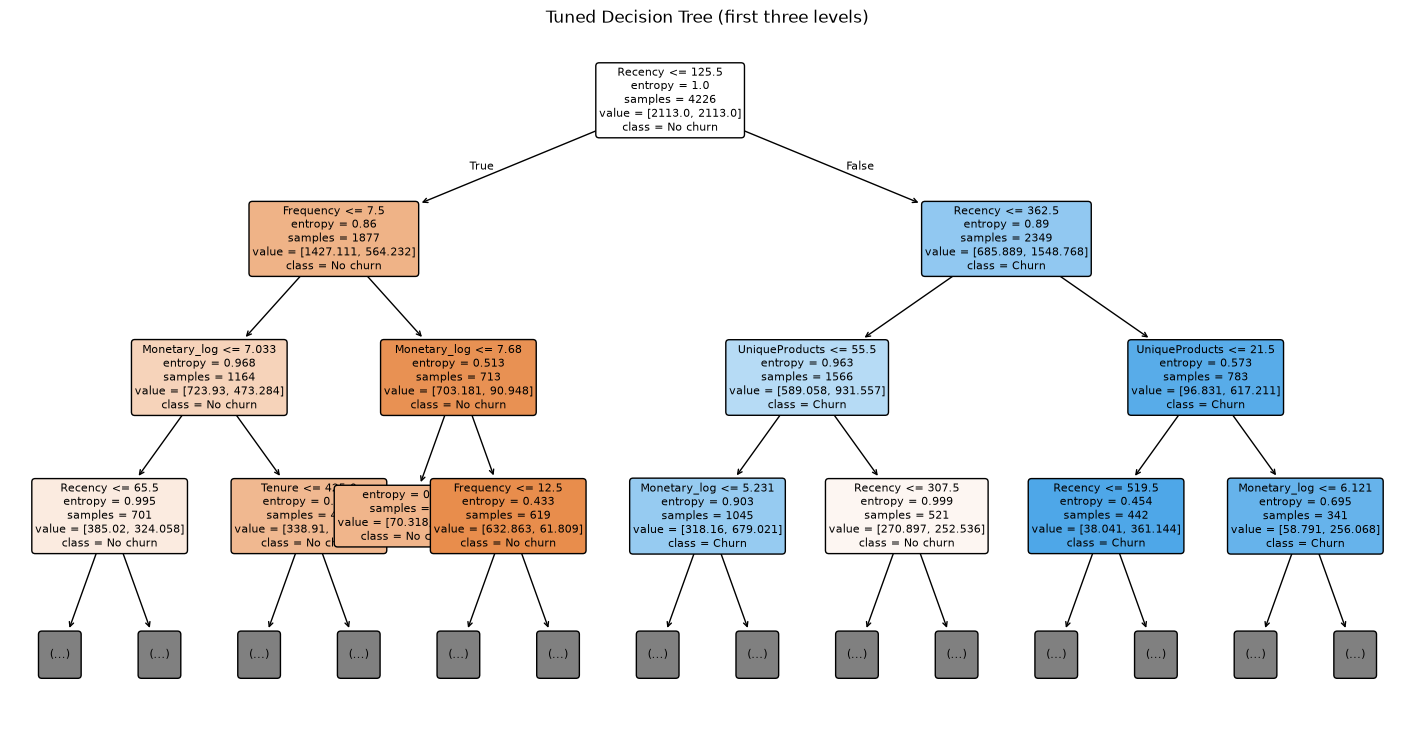

**Business interpretation:** The first business question is whether recency is at most 125.5. Lower recency means a more recent purchase, so the tree first separates recently active customers from less-recent customers, then applies different churn-risk rules to each group.


SECTION D - MODEL COMPARISON; SECTION F - REUSABLE EVALUATOR
evaluate_model returns CV mean/std, test metrics, and the predictions/probabilities reused below.

Logistic Regression CV (training fold means/std):


,train_mean,train_std,cv_mean,cv_std
accuracy,0.722,0.003,0.722,0.008
precision,0.774,0.002,0.774,0.007
recall,0.719,0.003,0.720,0.015
f1,0.746,0.003,0.746,0.009
roc_auc,0.797,0.003,0.794,0.013


Tuned tree CV (same five folds):


,train_mean,train_std,cv_mean,cv_std
accuracy,0.736,0.009,0.716,0.007
precision,0.772,0.014,0.752,0.020
recall,0.759,0.046,0.746,0.026
f1,0.764,0.017,0.748,0.005
roc_auc,0.813,0.005,0.781,0.014


...

Tree has higher fold F1 in 3 of 5 folds.
Final test metrics (each model predicted/scored once):


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.745,0.795,0.739,0.766,0.809
Tuned Decision Tree,0.735,0.784,0.734,0.758,0.807


No model or threshold changes follow these final test scores.


,CV F1,Test F1,Test minus CV F1
Logistic Regression,0.746,0.766,0.02
Tuned Decision Tree,0.748,0.758,0.01


Largest absolute CV/Test F1 gap=0.020; neither model has a large gap by this check.


In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             log_loss, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_validate, validation_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.pipeline import Pipeline

# Resolve the project data folder whether the notebook kernel starts in the repo or notebooks/.
data_dir = next((root / 'data' / 'processed' for root in (Path.cwd(), *Path.cwd().parents)
                 if (root / 'data' / 'processed' / 'X_train.csv').is_file()), None)
if data_dir is None:
    raise FileNotFoundError('Could not locate data/processed/X_train.csv from the current directory.')

X_train = pd.read_csv(data_dir / 'X_train.csv')
y_train = pd.read_csv(data_dir / 'y_train.csv').squeeze('columns')
X_test = pd.read_csv(data_dir / 'X_test.csv')
y_test_path = data_dir / 'y_test.csv'
if y_test_path.is_file():
    y_test = pd.read_csv(y_test_path).squeeze('columns')
else:
    prediction_path = data_dir / 'logreg_test_predictions.csv'
    if not prediction_path.is_file():
        raise FileNotFoundError('y_test.csv is missing and no test-prediction file is available for its actual labels.')
    previous_test = pd.read_csv(prediction_path)
    if 'actual' not in previous_test.columns or len(previous_test) != len(X_test):
        raise ValueError('Fallback test labels are missing or their row count does not match X_test.')
    y_test = previous_test['actual'].rename('Churned')
    print('NOTICE: y_test.csv is absent; using the row-aligned actual labels from logreg_test_predictions.csv.')

if len(X_train) != len(y_train) or len(X_test) != len(y_test):
    raise ValueError('Feature and target row counts do not match.')
if list(X_train.columns) != list(X_test.columns):
    raise ValueError('X_train and X_test feature columns or their order differ.')

num_cols = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts']
missing_num_cols = sorted(set(num_cols) - set(X_train.columns))
if missing_num_cols:
    raise ValueError(f'Expected scaled columns are missing: {missing_num_cols}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metric_names = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
CLASS_WEIGHT = 'balanced'
prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough')

def build_logreg(C=1.0, max_iter=5000):
    return Pipeline([
        ('prep', prep),
        ('model', LogisticRegression(C=C, max_iter=max_iter, class_weight='balanced')),
    ])

def evaluate_model(model, X_tr, y_tr, X_te, y_te, cv):
    """Return fold-level CV mean/std and a single final test score plus reused predictions."""
    scores = cross_validate(model, X_tr, y_tr, cv=cv, scoring=metric_names,
                            return_train_score=True, error_score='raise')
    cv_table = pd.DataFrame({
        'train_mean': [scores[f'train_{m}'].mean() for m in metric_names],
        'train_std': [scores[f'train_{m}'].std() for m in metric_names],
        'cv_mean': [scores[f'test_{m}'].mean() for m in metric_names],
        'cv_std': [scores[f'test_{m}'].std() for m in metric_names],
    }, index=metric_names)
    model.fit(X_tr, y_tr)
    test_pred = model.predict(X_te)
    test_proba = model.predict_proba(X_te)[:, 1]
    test_table = pd.DataFrame({
        'test_score': [
            accuracy_score(y_te, test_pred),
            precision_score(y_te, test_pred, zero_division=0),
            recall_score(y_te, test_pred, zero_division=0),
            f1_score(y_te, test_pred, zero_division=0),
            roc_auc_score(y_te, test_proba),
        ]
    }, index=metric_names)
    return cv_table, test_table, test_pred, test_proba, scores['test_f1']

print(f'Train: {X_train.shape}; test: {X_test.shape}; churn share train/test: '
      f'{y_train.mean():.3f}/{y_test.mean():.3f}')

# Section A1: scaled Logistic Regression; class_weight matches the earlier selection.
print('\nSECTION A - LOGISTIC REGRESSION')
initial_lr = build_logreg()
with warnings.catch_warnings(record=True) as initial_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    initial_lr.fit(X_train, y_train)
initial_iter = int(initial_lr.named_steps['model'].n_iter_[0])
print(f'Initial model n_iter_={initial_iter}; converged={len(initial_warnings) == 0}; '
      f'ConvergenceWarnings={len(initial_warnings)}')

# Section A2: training log-loss at each requested iteration limit.
iteration_limits = [1, 2, 5, 10, 50, 200]
loss_rows = []
for limit in iteration_limits:
    candidate = build_logreg(max_iter=limit)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        candidate.fit(X_train, y_train)
    loss_rows.append({
        'max_iter': limit,
        'n_iter': int(candidate.named_steps['model'].n_iter_[0]),
        'train_log_loss': log_loss(y_train, candidate.predict_proba(X_train)),
        'convergence_warnings': len(caught),
    })
loss_table = pd.DataFrame(loss_rows)
display(loss_table.round(4))
plt.figure(figsize=(7, 4))
plt.plot(loss_table['max_iter'], loss_table['train_log_loss'], marker='o')
plt.xscale('log')
plt.xticks(iteration_limits, iteration_limits)
plt.xlabel('max_iter')
plt.ylabel('Training log-loss')
plt.title('Logistic Regression convergence')
plt.grid(True, alpha=0.3)
plt.show()
best_observed_loss = loss_table['train_log_loss'].min()
near_best_iter = int(loss_table.loc[
    loss_table['train_log_loss'] <= best_observed_loss + 1e-3, 'max_iter'].iloc[0])
flat_pairs = np.flatnonzero(np.abs(np.diff(loss_table['train_log_loss'])) <= 1e-4)
print(f'Loss is within 0.001 of the best observed value by max_iter={near_best_iter}.')
if len(flat_pairs):
    print(f'It is effectively flat between max_iter={iteration_limits[flat_pairs[0]]} '
          f'and {iteration_limits[flat_pairs[0] + 1]}.')

# Section A3: choose C from training CV only; report train F1, CV F1, and their gap.
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
C_rows = []
for C in C_values:
    result = cross_validate(build_logreg(C=C), X_train, y_train, cv=cv, scoring='f1',
                            return_train_score=True, error_score='raise')
    C_rows.append({
        'C': C,
        'train_f1': result['train_score'].mean(),
        'cv_f1': result['test_score'].mean(),
        'cv_std': result['test_score'].std(),
    })
C_table = pd.DataFrame(C_rows)
C_table['gap_train_minus_cv'] = C_table['train_f1'] - C_table['cv_f1']
display(C_table.round(4))
best_cv = C_table['cv_f1'].max()
best_C = float(C_table.loc[C_table['cv_f1'].idxmax(), 'C'])
print(f'Chosen C={best_C:g}: highest mean training-CV F1 ({best_cv:.4f}); test data did not influence C.')

# Section A4: compare against unscaled Logistic Regression.
scaled_compare = build_logreg(C=best_C)
with warnings.catch_warnings(record=True) as scaled_compare_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    scaled_compare.fit(X_train, y_train)
scaled_compare_iter = int(scaled_compare.named_steps['model'].n_iter_[0])
unscaled_lr = LogisticRegression(C=best_C, max_iter=5000, class_weight='balanced')
with warnings.catch_warnings(record=True) as unscaled_warnings:
    warnings.simplefilter('always', ConvergenceWarning)
    unscaled_lr.fit(X_train, y_train)
unscaled_iter = int(unscaled_lr.n_iter_[0])
print(f'Same selected C={best_C:g}: scaled n_iter_={scaled_compare_iter} '
      f'(warnings={len(scaled_compare_warnings)}); unscaled n_iter_={unscaled_iter} '
      f'(warnings={len(unscaled_warnings)}).')
print('Scaling puts numeric features on comparable ranges, typically improving optimizer convergence; '
      'the observed iteration counts and warnings above are the evidence for this dataset.')

# Section C1: unconstrained tree and its train/CV F1 gap.
print('\nSECTION C - DECISION TREE')
unlimited_tree = DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42)
unlimited_tree.fit(X_train, y_train)
unlimited_depth = unlimited_tree.get_depth()
unlimited_leaves = unlimited_tree.get_n_leaves()
unlimited_train_accuracy = accuracy_score(y_train, unlimited_tree.predict(X_train))
unlimited_cv = cross_validate(unlimited_tree, X_train, y_train, cv=cv, scoring='f1',
                              return_train_score=True, error_score='raise')
unlimited_train_f1 = unlimited_cv['train_score'].mean()
unlimited_cv_f1 = unlimited_cv['test_score'].mean()
print(f'Unlimited tree depth={unlimited_depth}, leaves={unlimited_leaves}, '
      f'train accuracy={unlimited_train_accuracy:.3f}')
print(f'CV train F1={unlimited_train_f1:.3f}; CV F1={unlimited_cv_f1:.3f}; '
      f'gap={unlimited_train_f1 - unlimited_cv_f1:.3f} (overfitting / high variance).')

# Section C2-C3: validation curve and the one-standard-error depth.
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
depth_train, depth_cv = validation_curve(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train, param_name='max_depth', param_range=depths,
    cv=cv, scoring='f1',
)
depth_table = pd.DataFrame({
    'max_depth': depths,
    'train_f1': depth_train.mean(axis=1),
    'cv_f1': depth_cv.mean(axis=1),
    'cv_std': depth_cv.std(axis=1),
})
depth_table['gap'] = depth_table['train_f1'] - depth_table['cv_f1']
display(depth_table.round(3))
best_depth_row = depth_table.loc[depth_table['cv_f1'].idxmax()]
one_se_floor = best_depth_row['cv_f1'] - best_depth_row['cv_std']
simple_depth_row = depth_table[depth_table['cv_f1'] >= one_se_floor].sort_values('max_depth').iloc[0]
simple_depth = int(simple_depth_row['max_depth'])
best_depth = int(best_depth_row['max_depth'])
print(f'Best mean CV F1: {best_depth_row["cv_f1"]:.3f} at depth {best_depth}; '
      f'one-SE simplest depth: {simple_depth}; depth difference: {best_depth - simple_depth}.')
near_best_depths = depth_table.loc[depth_table['cv_f1'] >= one_se_floor, 'max_depth']
left_edge, right_edge = float(near_best_depths.min()), float(near_best_depths.max())
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depths, depth_table['train_f1'], marker='o', label='Train F1')
ax.plot(depths, depth_table['cv_f1'], marker='o', label='CV F1')
ax.fill_between(depths, 0, 1, where=np.array(depths) < left_edge, step='mid', alpha=0.10, color='red')
near_best_mask = depth_table['cv_f1'].to_numpy() >= one_se_floor
ax.fill_between(depths, 0, 1, where=near_best_mask,
                step='mid', alpha=0.10, color='green')
ax.fill_between(depths, 0, 1, where=np.array(depths) > right_edge, step='mid', alpha=0.10, color='orange')
ax.axhline(one_se_floor, color='gray', linestyle='--', label='Best CV F1 - 1 std')
ax.set(xlabel='max_depth', ylabel='F1', title='Decision Tree validation curve')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, alpha=0.25)
plt.show()
display(Markdown('**Underfit:** depths below the near-best band. **Sweet spot:** depths within one standard error of the best CV F1. **Overfit:** deeper trees past that band, especially as the train-CV gap grows.'))

# Section C4: min_samples_leaf effect at a fixed max_depth=10.
leaf_values = [1, 5, 10, 20, 50, 100, 200]
leaf_train, leaf_cv = validation_curve(
    DecisionTreeClassifier(max_depth=10, class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train, param_name='min_samples_leaf', param_range=leaf_values,
    cv=cv, scoring='f1',
)
leaf_table = pd.DataFrame({
    'min_samples_leaf': leaf_values,
    'train_f1': leaf_train.mean(axis=1),
    'cv_f1': leaf_cv.mean(axis=1),
})
display(leaf_table.round(3))
leaf_effect = leaf_table['cv_f1'].max() - leaf_table['cv_f1'].min()
depth_effect = depth_table['cv_f1'].max() - depth_table['cv_f1'].min()
print(f'CV-F1 range: max_depth={depth_effect:.3f}; min_samples_leaf={leaf_effect:.3f}. '
      f'On this grid, leaf size is {"at least as influential" if leaf_effect >= depth_effect else "less influential"} by this range measure.')

# Section C5: required grid; every tree uses random_state=42.
param_grid = {
    'max_depth': [3, 4, 5, 6, 8],
    'min_samples_leaf': [5, 20, 50, 100],
    'min_samples_split': [2, 20, 50],
    'criterion': ['gini', 'entropy'],
}
grid = GridSearchCV(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    param_grid=param_grid, cv=cv, scoring='f1', refit=True,
    return_train_score=True, error_score='raise',
)
grid.fit(X_train, y_train)
print('GridSearchCV best_params_ (training CV only):', grid.best_params_)
grid_results = pd.DataFrame(grid.cv_results_)
top8 = grid_results.sort_values(['rank_test_score', 'mean_test_score'], ascending=[True, False]).head(8)
display(top8[['rank_test_score', 'mean_test_score', 'std_test_score', 'mean_train_score',
              'param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split',
              'param_criterion']].reset_index(drop=True).round(4))
# Among candidates within one CV std of the best, prefer shallower/smoother trees.
best_grid_row = grid_results.loc[grid_results['mean_test_score'].idxmax()]
grid_floor = best_grid_row['mean_test_score'] - best_grid_row['std_test_score']
simple_candidates = grid_results[grid_results['mean_test_score'] >= grid_floor].copy()
simple_candidates = simple_candidates.sort_values(
    ['param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split', 'param_criterion'],
    ascending=[True, False, False, True],
)
chosen_params = {key: simple_candidates.iloc[0][f'param_{key}']
                 for key in param_grid}
print(f'Best mean CV F1={best_grid_row["mean_test_score"]:.4f}; '
      f'one-SE-simple choice={chosen_params}. Similar scores favor a shallower tree, '
      'larger leaves/split minimums, and gini only as a final tie-break.')
final_tree = DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42, **chosen_params)

# Section C6 and model-evaluation helper are completed below.
print('\nSECTION B - FINAL LOGISTIC REGRESSION PREDICTIONS')
final_logreg = build_logreg(C=best_C)
cv_logreg, test_logreg, pred_logreg, proba_logreg, logreg_fold_f1 = evaluate_model(
    final_logreg, X_train, y_train, X_test, y_test, cv)
print(f'Final scaled LogReg n_iter_={int(final_logreg.named_steps["model"].n_iter_[0])}; '
      f'unscaled counterpart n_iter_={unscaled_iter}; warnings scaled/unscaled='
      f'{len(initial_warnings)}/{len(unscaled_warnings)}.')
print('predict() equals (predict_proba()[:, 1] >= 0.5):',
      bool(np.array_equal(pred_logreg, (proba_logreg >= 0.5).astype(pred_logreg.dtype))))

# Manual single-row probability: intercept + dot(coef, scaled row), then sigmoid.
row_number = 0
scaled_row = final_logreg.named_steps['prep'].transform(X_test.iloc[[row_number]])
lr_estimator = final_logreg.named_steps['model']
manual_logit = float(lr_estimator.intercept_[0] + np.dot(lr_estimator.coef_[0], scaled_row[0]))
manual_probability = float(1.0 / (1.0 + np.exp(-manual_logit)))
pipeline_probability = float(proba_logreg[row_number])
print(f'Row {row_number}: intercept + dot = {manual_logit:.8f}; sigmoid = {manual_probability:.8f}; '
      f'predict_proba = {pipeline_probability:.8f}; match={np.isclose(manual_probability, pipeline_probability)}')

# Test thresholds are diagnostic only; these same saved probabilities are reused, not re-predicted.
threshold_rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    threshold_pred = (proba_logreg >= threshold).astype(y_test.dtype)
    threshold_rows.append({
        'threshold': threshold,
        'flagged_customers': int(threshold_pred.sum()),
        'precision': precision_score(y_test, threshold_pred, zero_division=0),
        'recall': recall_score(y_test, threshold_pred, zero_division=0),
    })
display(pd.DataFrame(threshold_rows).round(3))
print('Never select a threshold from this test table: that would adapt to the exam answers. '
      'Choose it using training-only out-of-fold/validation probabilities (or nested CV), then lock it before test evaluation.')

# Plot the tuned tree and translate its root condition into customer language.
final_tree.fit(X_train, y_train)
root_index = int(final_tree.tree_.feature[0])
root_feature = X_train.columns[root_index]
root_threshold = float(final_tree.tree_.threshold[0])
print(f'Chosen tree root: {root_feature} <= {root_threshold:.4g}')
print(export_text(final_tree, feature_names=list(X_train.columns), max_depth=3))
plt.figure(figsize=(18, 9))
plot_tree(final_tree, feature_names=list(X_train.columns), class_names=['No churn', 'Churn'],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title('Tuned Decision Tree (first three levels)')
plt.show()
if root_feature == 'Recency':
    root_explanation = (f'The first business question is whether recency is at most {root_threshold:.4g}. '
                        'Lower recency means a more recent purchase, so the tree first separates recently active customers '
                        'from less-recent customers, then applies different churn-risk rules to each group.')
elif root_feature == 'Frequency':
    root_explanation = (f'The first question is whether order frequency is at most {root_threshold:.4g}. '
                        'This separates less-frequent from more-frequent customers before later churn-risk checks.')
else:
    root_explanation = (f'The tree first separates customers with {root_feature} <= {root_threshold:.4g} from those above it. '
                        'That first customer segment determines which downstream churn-risk rules are considered.')
display(Markdown('**Business interpretation:** ' + root_explanation))

# Section D and F: one reusable evaluator; both models use the same cv object.
print('\nSECTION D - MODEL COMPARISON; SECTION F - REUSABLE EVALUATOR')
cv_tree, test_tree, pred_tree, proba_tree, tree_fold_f1 = evaluate_model(
    final_tree, X_train, y_train, X_test, y_test, cv)
print('evaluate_model returns CV mean/std, test metrics, and the predictions/probabilities reused below.')
print('\nLogistic Regression CV (training fold means/std):')
display(cv_logreg.round(3))
print('Tuned tree CV (same five folds):')
display(cv_tree.round(3))
fold_f1 = pd.DataFrame({'LogReg F1': logreg_fold_f1, 'Tree F1': tree_fold_f1})
fold_f1['Tree minus LogReg'] = fold_f1['Tree F1'] - fold_f1['LogReg F1']
display(fold_f1.round(3))
tree_wins = int((fold_f1['Tree minus LogReg'] > 0).sum())
print(f'Tree has higher fold F1 in {tree_wins} of 5 folds.')

test_comparison = pd.DataFrame({
    'CV F1': [cv_logreg.loc['f1', 'cv_mean'], cv_tree.loc['f1', 'cv_mean']],
    'Test F1': [test_logreg.loc['f1', 'test_score'], test_tree.loc['f1', 'test_score']],
}, index=['Logistic Regression', 'Tuned Decision Tree'])
test_comparison['Test minus CV F1'] = test_comparison['Test F1'] - test_comparison['CV F1']
print('Final test metrics (each model predicted/scored once):')
display(pd.concat({'Logistic Regression': test_logreg['test_score'],
                    'Tuned Decision Tree': test_tree['test_score']}, axis=1).T.round(3))
print('No model or threshold changes follow these final test scores.')
display(test_comparison.round(3))
largest_gap = test_comparison['Test minus CV F1'].abs().max()
print(f'Largest absolute CV/Test F1 gap={largest_gap:.3f}; '
      f'{"a gap worth investigating" if largest_gap >= 0.05 else "neither model has a large gap by this check"}.')

# Paired bootstrap: resample test-row indices, never refit models.
rng = np.random.default_rng(42)
y_array = np.asarray(y_test)
boot_logreg, boot_tree, boot_difference = [], [], []
for _ in range(1000):
    sample_idx = rng.integers(0, len(y_array), size=len(y_array))
    f1_lr = f1_score(y_array[sample_idx], pred_logreg[sample_idx], zero_division=0)
    f1_dt = f1_score(y_array[sample_idx], pred_tree[sample_idx], zero_division=0)
    boot_logreg.append(f1_lr)
    boot_tree.append(f1_dt)
    boot_difference.append(f1_dt - f1_lr)
def percentile_ci(values):
    return np.percentile(values, [2.5, 97.5])
ci_lr = percentile_ci(boot_logreg)
ci_tree = percentile_ci(boot_tree)
ci_diff = percentile_ci(boot_difference)
bootstrap_table = pd.DataFrame({
    'estimate': [f1_score(y_test, pred_logreg), f1_score(y_test, pred_tree),
                 f1_score(y_test, pred_tree) - f1_score(y_test, pred_logreg)],
    '95% CI low': [ci_lr[0], ci_tree[0], ci_diff[0]],
    '95% CI high': [ci_lr[1], ci_tree[1], ci_diff[1]],
}, index=['LogReg F1', 'Tree F1', 'Tree - LogReg F1'])
display(bootstrap_table.round(3))
if ci_diff[0] <= 0 <= ci_diff[1]:
    print('The paired 95% bootstrap interval for Tree minus LogReg includes zero: the test-set difference is not statistically clear.')
else:
    print('The paired 95% bootstrap interval excludes zero: the test-set difference is statistically clear by this interval.')

# Confusion matrices reuse the one set of predictions per model.
for name, predictions in [('Logistic Regression', pred_logreg), ('Tuned Decision Tree', pred_tree)]:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    print(f'{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; missed churners (FN)={fn}')
fn_lr = confusion_matrix(y_test, pred_logreg, labels=[0, 1]).ravel()[2]
fn_tree = confusion_matrix(y_test, pred_tree, labels=[0, 1]).ravel()[2]
print('More missed churners:', 'Logistic Regression' if fn_lr > fn_tree else
      'Tuned Decision Tree' if fn_tree > fn_lr else 'tie')

# Section F: both models were evaluated through this generic estimator-compatible function.
print('Section F complete: evaluate_model(final_logreg, ...) and evaluate_model(final_tree, ...) '
      'returned CV mean/std tables and test tables; the saved prediction arrays power all later diagnostics.')

## Section E - Conceptual answers

1. **Hyperparameter vs parameter:** A hyperparameter is fixed before fitting and controls learning; examples are Logistic Regression's `C` and a Decision Tree's `max_depth`. A parameter is learned from training rows; examples are Logistic Regression's `coef_` and `intercept_`, and the tree's split features/thresholds.
2. **Why test-set tuning is wrong:** repeatedly changing a churn threshold or tree depth after looking at test F1 makes decisions fit random quirks of those test customers. The reported score then becomes an optimistic estimate of the process used to select it, not an independent exam result. Use training-only CV (or nested CV) for choices, lock the model, then evaluate on test.
3. **Production if scores are similar:** I would usually start with Logistic Regression when its scaled pipeline and probability calibration are adequate: it is compact, stable, and coefficients are relatively easy to explain. A tree is easier to communicate as explicit rules and does not need feature scaling, but small data changes can alter its splits and its leaf probabilities may be coarse. I would compare calibration on training-only validation data and choose based on the cost of missed churners and operational interpretability, not the test score alone.
4. **GridSearchCV optimism:** it reports the best score among many noisy CV estimates. Selecting the maximum makes it likely that the winning configuration benefited from favorable fold noise; an untouched test set or nested CV gives a less biased estimate of the complete selection procedure.